## Does the 0.59 depend on the full sample?

Notebook 2 fits seven terms to the 2016–2024 average for each offered county and gets an adjusted R² of 0.59. Four terms had intervals that excluded zero: log population, the uninsured rate, unemployment, and the benchmark Silver premium. This notebook keeps those four and asks whether the fit was the other three terms, a particular stretch of years, one region, the split between Kaiser's Northern and Southern California regions, or a single county.

The sample rules match notebook 2. A county enters if Kaiser was offered there. Monterey is out, because its service area opens in 2025. Los Angeles is out of every fit here, because it has no benchmark premium. A coefficient is percentage points of Kaiser share. Intervals use HC1 standard errors.

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import HTML, Markdown, display

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})

FOUR_FORMULA = (
    "kp_market_share ~ log_population + uninsured_rate + unemployment_rate "
    "+ benchmark_silver_premium"
)
FULL_FORMULA = (
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate "
    "+ unemployment_rate + carrier_count + benchmark_silver_premium"
)
TERMS = [
    ("log_population", "Population", "per doubling", np.log(2) * 100),
    ("uninsured_rate", "Uninsured rate", "per percentage point", 100),
    ("unemployment_rate", "Unemployment rate", "per percentage point", 100),
    ("benchmark_silver_premium", "Benchmark Silver premium", "per $10", 1000),
]
FOUR_COLUMNS = [
    "kp_market_share",
    "log_population",
    "uninsured_rate",
    "unemployment_rate",
    "benchmark_silver_premium",
]
FULL_COLUMNS = FOUR_COLUMNS + ["income_10k", "poverty_rate", "carrier_count"]
REGION = {
    "Alameda": "Bay Area",
    "Contra Costa": "Bay Area",
    "Marin": "Bay Area",
    "Napa": "Bay Area",
    "San Francisco": "Bay Area",
    "San Mateo": "Bay Area",
    "Santa Clara": "Bay Area",
    "Santa Cruz": "Bay Area",
    "Solano": "Bay Area",
    "Sonoma": "Bay Area",
    "Sacramento": "Sacramento and the foothills",
    "Placer": "Sacramento and the foothills",
    "El Dorado": "Sacramento and the foothills",
    "Yolo": "Sacramento and the foothills",
    "Yuba": "Sacramento and the foothills",
    "Sutter": "Sacramento and the foothills",
    "Amador": "Sacramento and the foothills",
    "Mariposa": "Sacramento and the foothills",
    "San Joaquin": "San Joaquin Valley",
    "Stanislaus": "San Joaquin Valley",
    "Fresno": "San Joaquin Valley",
    "Kern": "San Joaquin Valley",
    "Kings": "San Joaquin Valley",
    "Madera": "San Joaquin Valley",
    "Tulare": "San Joaquin Valley",
    "Imperial": "Southern California",
    "Orange": "Southern California",
    "Riverside": "Southern California",
    "San Bernardino": "Southern California",
    "San Diego": "Southern California",
    "Ventura": "Southern California",
}


def format_p(p_value):
    if p_value < 0.001:
        return "<0.001"
    return f"{p_value:.3f}"


def name_list(items):
    if len(items) == 1:
        return items[0]
    if len(items) == 2:
        return f"{items[0]} and {items[1]}"
    return ", ".join(items[:-1]) + f", and {items[-1]}"


def fit_terms(formula, frame):
    return smf.ols(formula, data=frame).fit(cov_type="HC1")


def scaled(fit, name, scale):
    low, high = fit.conf_int().loc[name] * scale
    return float(fit.params[name] * scale), float(low), float(high), float(fit.pvalues[name])


def short_county(name):
    return name.replace(" County", "")


def prepare(frame):
    prepared = frame.copy()
    prepared["log_population"] = np.log(prepared["population_total"])
    prepared["income_10k"] = prepared["median_household_income"] / 10000
    prepared["county"] = prepared["county_name"].map(short_county)
    return prepared


con = duckdb.connect("../data/processed/analysis.duckdb", read_only=True)
market = con.sql("select * from main_marts.mart_cty_yr_market").df()
performance = con.sql("select * from main_marts.mart_cty_yr_performance").df()
socioeconomic = con.sql("select * from main_marts.mart_cty_yr_socioeconomic").df()
panel = (
    market.merge(performance, on=["county_fips", "year"], how="left", suffixes=("", "_performance"))
    .merge(socioeconomic, on=["county_fips", "year"], how="left", suffixes=("", "_socio"))
)
offered = panel[panel["kp_offered"] & panel["year"].between(2016, 2024)].copy()
measure_cols = [
    "kp_market_share",
    "population_total",
    "median_household_income",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
]
county = prepare(offered.groupby(["county_fips", "county_name"], as_index=False)[measure_cols].mean())
annual = prepare(offered)
sample = county.dropna(subset=FULL_COLUMNS).copy()
sample["region"] = sample["county"].map(REGION)
if sample["region"].isna().any():
    missing = sample.loc[sample["region"].isna(), "county"].tolist()
    raise ValueError(f"No region for {missing}")
reference = fit_terms(FOUR_FORMULA, sample)
reference_sign = {name: np.sign(reference.params[name]) for name, *_ in TERMS}

## Four terms instead of seven

Model 2 from notebook 2 includes income, poverty, and carrier count alongside the four terms. Those three had intervals that included zero. The comparison below refits both equations on the same 31 counties.


In [2]:
full = fit_terms(FULL_FORMULA, sample)
fits = {"Seven terms": full, "Four terms": reference}
fit_rows = []
for label, fit in fits.items():
    fit_rows.append({
        "specification": label,
        "counties": int(fit.nobs),
        "terms": int(fit.df_model),
        "r_squared": f"{fit.rsquared:.2f}",
        "adjusted_r_squared": f"{fit.rsquared_adj:.2f}",
    })
display(HTML(pd.DataFrame(fit_rows).to_html(index=False)))

comparison_rows = []
for name, label, unit, scale in TERMS:
    row = {"term": label, "unit": unit}
    for spec, fit in fits.items():
        estimate, low, high, p_value = scaled(fit, name, scale)
        row[f"{spec} estimate"] = f"{estimate:.1f} ({low:.1f}, {high:.1f})"
        row[f"{spec} p"] = format_p(p_value)
    comparison_rows.append(row)
display(HTML(pd.DataFrame(comparison_rows).to_html(index=False)))

four_adj = reference.rsquared_adj
seven_adj = full.rsquared_adj
display(Markdown(
    f"The four-term equation has an adjusted R² of **{four_adj:.2f}**, "
    f"against **{seven_adj:.2f}** for the seven-term equation. "
    "Income, poverty, and carrier count are not what produces the fit."
))


specification,counties,terms,r_squared,adjusted_r_squared
Seven terms,31,7,0.68,0.59
Four terms,31,4,0.65,0.60


term,unit,Seven terms estimate,Seven terms p,Four terms estimate,Four terms p
Population,per doubling,"8.7 (2.9, 14.5)",0.003,"5.9 (2.3, 9.5)",0.001
Uninsured rate,per percentage point,"-8.1 (-14.9, -1.2)",0.021,"-5.0 (-10.0, -0.1)",0.047
Unemployment rate,per percentage point,"-2.4 (-4.2, -0.6)",0.007,"-1.5 (-3.0, -0.1)",0.042
Benchmark Silver premium,per $10,"1.7 (0.1, 3.4)",0.038,"1.5 (0.2, 2.8)",0.024


The four-term equation has an adjusted R² of **0.60**, against **0.59** for the seven-term equation. Income, poverty, and carrier count are not what produces the fit.

## Each year, and an early window against a late one

A year is one row per offered county in that year, not a nine-year average. The windows average 2016–2019 and 2020–2024, one row per county, so they can be set next to the 2016–2024 average. The early window contains the drop in the uninsured rate. The later window is the years after that drop.


**Single years.** An estimate is shown with its p-value. Units match the table above.

slice,counties,adjusted_r_squared,Population,Uninsured rate,Unemployment rate,Benchmark Silver premium
2016,30,0.63,5.0 (<0.001),-0.4 (0.811),-1.0 (0.083),2.9 (<0.001)
2017,31,0.66,5.8 (<0.001),-0.9 (0.665),-1.6 (0.043),2.8 (<0.001)
2018,31,0.50,6.5 (0.019),-6.0 (0.007),-1.2 (0.217),1.0 (0.097)
2019,31,0.56,6.3 (0.009),-8.2 (<0.001),-1.0 (0.183),1.0 (0.077)
2020,31,0.58,5.0 (0.003),-7.5 (0.005),-1.9 (0.005),1.1 (0.058)
2021,31,0.56,5.4 (0.002),-5.5 (0.033),-2.8 (0.004),1.3 (0.030)
2022,31,0.58,5.0 (0.003),-4.5 (0.159),-3.3 (<0.001),1.7 (0.050)
2023,31,0.62,4.6 (0.002),-5.7 (0.011),-2.6 (<0.001),1.3 (0.028)
2024,31,0.61,4.9 (0.004),-6.5 (0.002),-2.1 (0.009),1.2 (0.009)


**Windows of county averages.**

slice,counties,adjusted_r_squared,Population,Uninsured rate,Unemployment rate,Benchmark Silver premium
2016–2019 averages,31,0.57,6.6 (0.002),-3.6 (0.119),-0.9 (0.213),1.8 (0.014)
2020–2024 averages,31,0.60,5.0 (0.002),-6.0 (0.017),-2.5 (0.002),1.3 (0.030)
2016–2024 averages,31,0.60,5.9 (0.001),-5.0 (0.047),-1.5 (0.042),1.5 (0.024)


Single-year adjusted R² runs from **0.50** to **0.66** (median **0.58**). The 2020–2024 averages have an adjusted R² of **0.60**. All four signs in that later window match the full-period four-term fit.

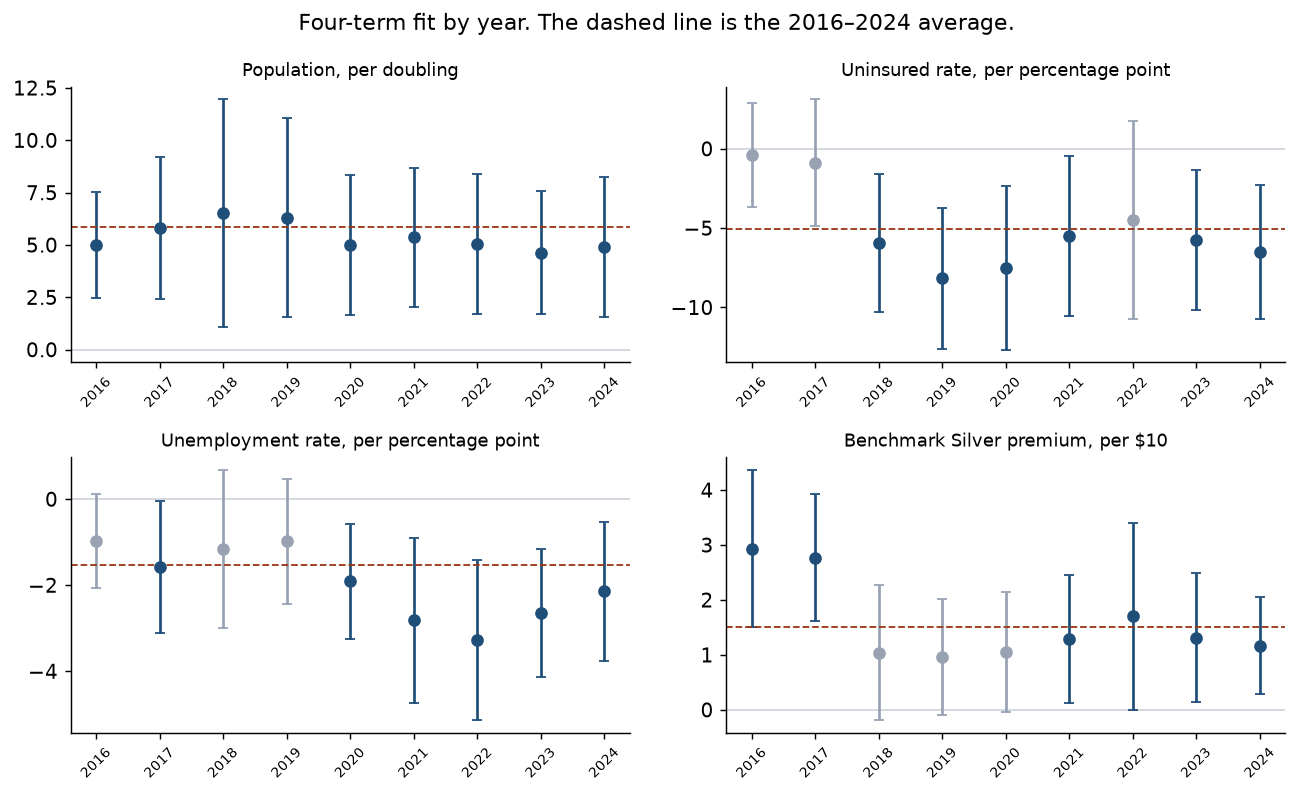

In [3]:
def coefficient_cells(fit):
    cells = {}
    for name, label, unit, scale in TERMS:
        estimate, low, high, p_value = scaled(fit, name, scale)
        cells[label] = f"{estimate:.1f} ({format_p(p_value)})"
    return cells


year_fits = {}
year_rows = []
for year, frame in annual.dropna(subset=FOUR_COLUMNS).groupby("year"):
    fit = fit_terms(FOUR_FORMULA, frame)
    year_fits[int(year)] = fit
    year_rows.append({
        "slice": str(int(year)),
        "counties": int(fit.nobs),
        "adjusted_r_squared": f"{fit.rsquared_adj:.2f}",
        **coefficient_cells(fit),
    })


def window_sample(start, end):
    subset = offered[offered["year"].between(start, end)]
    means = prepare(subset.groupby(["county_fips", "county_name"], as_index=False)[measure_cols].mean())
    return means.dropna(subset=FOUR_COLUMNS)


window_fits = {}
window_rows = []
for label, start, end in [
    ("2016–2019 averages", 2016, 2019),
    ("2020–2024 averages", 2020, 2024),
    ("2016–2024 averages", 2016, 2024),
]:
    fit = fit_terms(FOUR_FORMULA, window_sample(start, end))
    window_fits[label] = fit
    window_rows.append({
        "slice": label,
        "counties": int(fit.nobs),
        "adjusted_r_squared": f"{fit.rsquared_adj:.2f}",
        **coefficient_cells(fit),
    })

display(Markdown("**Single years.** An estimate is shown with its p-value. Units match the table above."))
display(HTML(pd.DataFrame(year_rows).to_html(index=False)))
display(Markdown("**Windows of county averages.**"))
display(HTML(pd.DataFrame(window_rows).to_html(index=False)))

year_adj = pd.Series({year: fit.rsquared_adj for year, fit in year_fits.items()})
late = window_fits["2020–2024 averages"]
late_same_sign = all(
    np.sign(late.params[name]) == reference_sign[name] for name, *_ in TERMS
)
display(Markdown(
    f"Single-year adjusted R² runs from **{year_adj.min():.2f}** to **{year_adj.max():.2f}** "
    f"(median **{year_adj.median():.2f}**). "
    f"The 2020–2024 averages have an adjusted R² of **{late.rsquared_adj:.2f}**. "
    + (
        "All four signs in that later window match the full-period four-term fit."
        if late_same_sign
        else "At least one sign in that later window differs from the full-period four-term fit."
    )
))

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (name, label, unit, scale) in zip(axes.ravel(), TERMS):
    years = sorted(year_fits)
    estimates, lows, highs = [], [], []
    for year in years:
        estimate, low, high, _ = scaled(year_fits[year], name, scale)
        estimates.append(estimate)
        lows.append(low)
        highs.append(high)
    estimates = np.array(estimates)
    lows = np.array(lows)
    highs = np.array(highs)
    ax.axhline(0, color="#d0d5dd", linewidth=1)
    for year, estimate, low, high in zip(years, estimates, lows, highs):
        color = "#1f4e79" if low > 0 or high < 0 else "#98a2b3"
        ax.errorbar(year, estimate, yerr=[[estimate - low], [high - estimate]], fmt="o", color=color, ecolor=color, capsize=3)
    full_estimate, _, _, _ = scaled(reference, name, scale)
    ax.axhline(full_estimate, color="#9a3412", linestyle="--", linewidth=1)
    ax.set_title(f"{label}, {unit}", fontsize=10)
    ax.set_xticks(years)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("Four-term fit by year. The dashed line is the 2016–2024 average.", fontsize=12)
fig.tight_layout()


## One region left out

The 31 counties are split into four groups. Santa Cruz is included with the Bay Area. Amador and Mariposa are included with Sacramento and the foothills. Imperial is included with Southern California. Each fit drops one group and keeps the other three. Thirty-one counties are too few for a separate equation inside each group.


left out,counties left out,counties in the fit,adjusted_r_squared,Population,Uninsured rate,Unemployment rate,Benchmark Silver premium
Bay Area,10,21,0.48,7.2 (0.005),-7.8 (<0.001),-0.6 (0.448),0.9 (0.241)
Sacramento and the foothills,8,23,0.68,-1.1 (0.623),-3.5 (0.398),-2.8 (<0.001),1.6 (0.121)
San Joaquin Valley,7,24,0.63,6.5 (<0.001),-4.8 (0.064),-1.5 (0.043),2.0 (0.001)
Southern California,6,25,0.72,6.0 (<0.001),6.0 (0.038),-12.5 (<0.001),0.4 (0.499)


**Bay Area.** Alameda, Contra Costa, Marin, Napa, San Francisco, San Mateo, Santa Clara, Santa Cruz, Solano, Sonoma.

**Sacramento and the foothills.** Amador, El Dorado, Mariposa, Placer, Sacramento, Sutter, Yolo, Yuba.

**San Joaquin Valley.** Fresno, Kern, Kings, Madera, San Joaquin, Stanislaus, Tulare.

**Southern California.** Imperial, Orange, Riverside, San Bernardino, San Diego, Ventura.

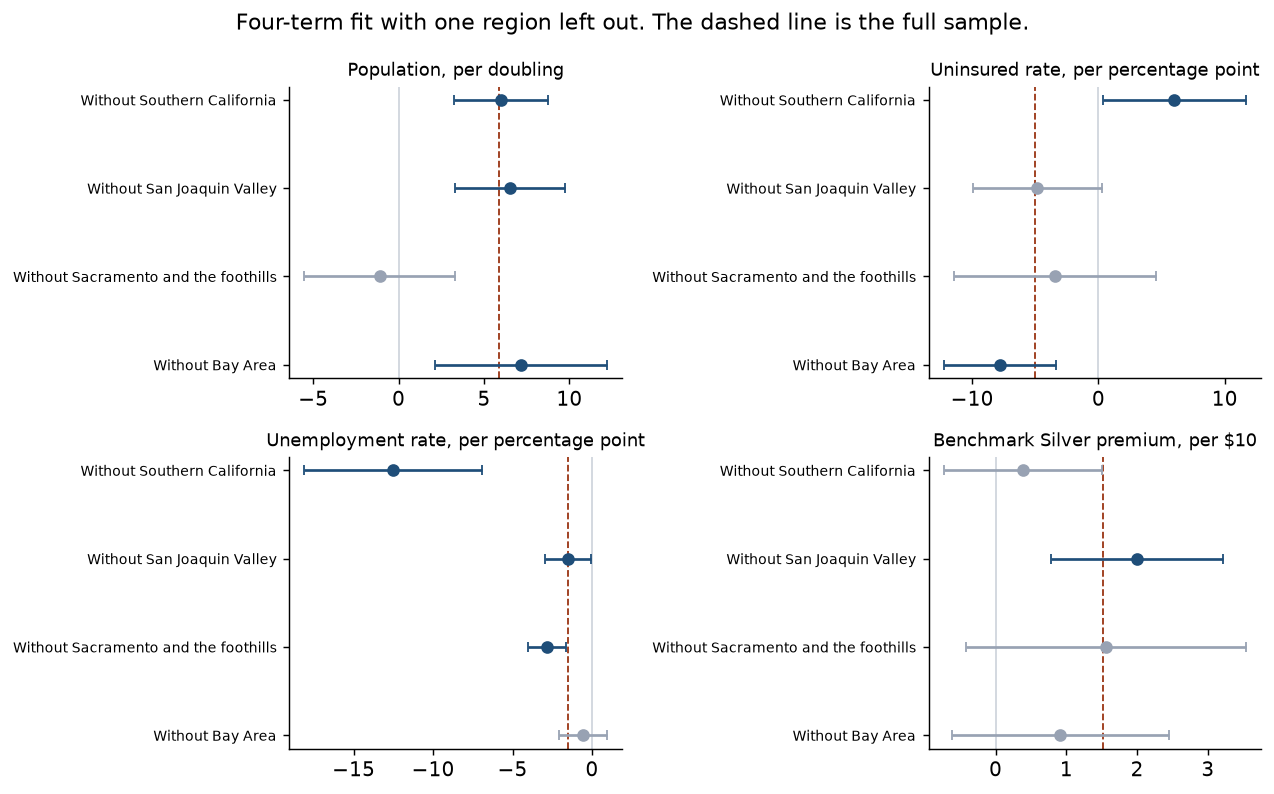

In [4]:
region_order = [
    "Bay Area",
    "Sacramento and the foothills",
    "San Joaquin Valley",
    "Southern California",
]
region_rows = []
region_fits = {}
for region in region_order:
    held = sample[sample["region"].eq(region)]
    kept = sample[sample["region"].ne(region)]
    fit = fit_terms(FOUR_FORMULA, kept)
    region_fits[region] = fit
    region_rows.append({
        "left out": region,
        "counties left out": int(held["county"].nunique()),
        "counties in the fit": int(fit.nobs),
        "adjusted_r_squared": f"{fit.rsquared_adj:.2f}",
        **coefficient_cells(fit),
    })
display(HTML(pd.DataFrame(region_rows).to_html(index=False)))

membership = (
    sample.groupby("region")["county"]
    .apply(lambda names: ", ".join(sorted(names)))
    .reindex(region_order)
)
display(Markdown(
    "\n\n".join(f"**{region}.** {names}." for region, names in membership.items())
))

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (name, label, unit, scale) in zip(axes.ravel(), TERMS):
    ax.axvline(0, color="#d0d5dd", linewidth=1)
    full_estimate, _, _, _ = scaled(reference, name, scale)
    ax.axvline(full_estimate, color="#9a3412", linestyle="--", linewidth=1)
    for position, region in enumerate(region_order):
        estimate, low, high, _ = scaled(region_fits[region], name, scale)
        color = "#1f4e79" if low > 0 or high < 0 else "#98a2b3"
        ax.errorbar(
            estimate,
            position,
            xerr=[[estimate - low], [high - estimate]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=3,
        )
    ax.set_yticks(range(len(region_order)))
    ax.set_yticklabels([f"Without {region}" for region in region_order], fontsize=8)
    ax.set_title(f"{label}, {unit}", fontsize=10)
fig.suptitle("Four-term fit with one region left out. The dashed line is the full sample.", fontsize=12)
fig.tight_layout()


## Northern and Southern California

Kaiser runs Northern and Southern California as separate regions. Seven counties in this sample sit in Southern California: Imperial, Kern, Orange, Riverside, San Bernardino, San Diego, and Ventura. Kern is placed there because Kaiser serves it from its Southern California region. The row with Kern moved north shows that the placement does not change the result.

Three fits are compared with the 31-county four-term fit. The region alone. The four terms plus a Southern California indicator, which compares counties with the same conditions on either side of the split. The four terms on the Northern California counties only. Seven Southern counties are too few for a separate equation.

**Estimates with p-values.** Southern California is the difference in share, in percentage points, against Northern California counties. Other units match the tables above.

specification,counties,adjusted_r_squared,Southern California,Population,Uninsured rate,Unemployment rate,Benchmark Silver premium
Southern California alone,31,0.17,-27.0 (<0.001),,,,
"Four terms, all counties",31,0.60,,5.9 (0.001),-5.0 (0.047),-1.5 (0.042),1.5 (0.024)
Four terms plus Southern California,31,0.63,-19.2 (0.037),7.4 (<0.001),-3.8 (0.179),-1.2 (0.238),1.1 (0.073)
"Four terms, Northern California only",24,0.71,,6.2 (<0.001),6.0 (0.041),-12.3 (<0.001),0.3 (0.580)
"Four terms plus Southern California, Kern north",31,0.63,-18.0 (0.028),7.1 (<0.001),-4.0 (0.145),-1.4 (0.206),1.2 (0.056)


Median share is **55%** in Northern California counties and **24%** in Southern California counties. The region alone has an adjusted R² of **0.17**. Adding it to the four terms gives **0.63**, and a Southern county sits **19 points** below a Northern county with the same conditions. With the region in the equation, the interval excludes zero for population and includes zero for uninsured rate, unemployment rate, and benchmark Silver premium. Inside the **24** Northern California counties, adjusted R² is **0.71**. The interval excludes zero for population, uninsured rate, and unemployment rate and includes zero for benchmark Silver premium. The uninsured coefficient there is **+6.0** points per percentage point. Moving Kern north gives a Southern difference of **-18.0** points and an adjusted R² of **0.63**.

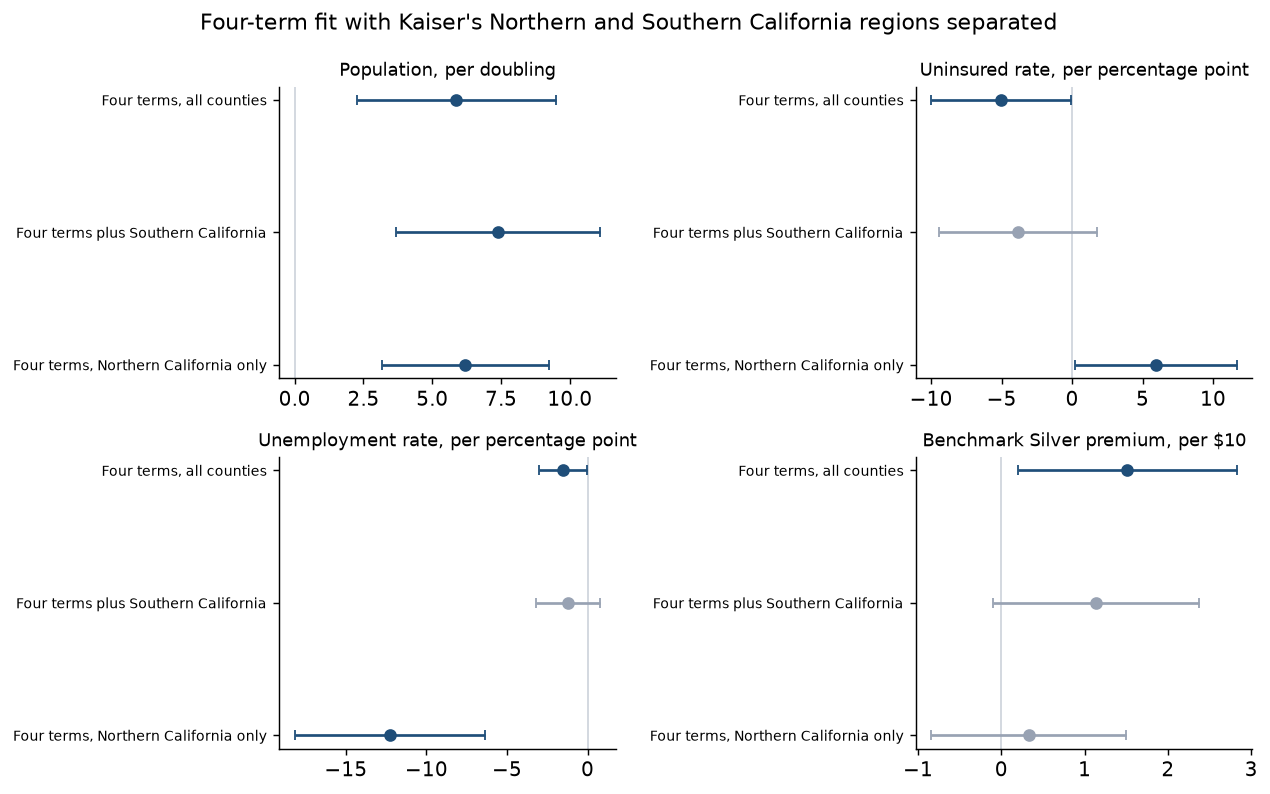

In [5]:
SOUTHERN = ["Imperial", "Kern", "Orange", "Riverside", "San Bernardino", "San Diego", "Ventura"]
SPLIT_FORMULA = FOUR_FORMULA + " + southern"


def mark_southern(frame, southern):
    marked = frame.copy()
    marked["southern"] = marked["county"].isin(southern).astype(int)
    return marked


def southern_cell(fit):
    if "southern" not in fit.params:
        return ""
    return f"{fit.params['southern'] * 100:.1f} ({format_p(fit.pvalues['southern'])})"


def clear_terms(fit):
    clear, unclear = [], []
    for name, label, unit, scale in TERMS:
        _, low, high, _ = scaled(fit, name, scale)
        (clear if low > 0 or high < 0 else unclear).append(label[0].lower() + label[1:])
    return clear, unclear


split_sample = mark_southern(sample, SOUTHERN)
region_alone = fit_terms("kp_market_share ~ southern", split_sample)
split_fits = {
    "Four terms, all counties": reference,
    "Four terms plus Southern California": fit_terms(SPLIT_FORMULA, split_sample),
    "Four terms, Northern California only": fit_terms(FOUR_FORMULA, split_sample[split_sample["southern"].eq(0)]),
}
kern_north = fit_terms(SPLIT_FORMULA, mark_southern(sample, [name for name in SOUTHERN if name != "Kern"]))

split_rows = [{
    "specification": "Southern California alone",
    "counties": int(region_alone.nobs),
    "adjusted_r_squared": f"{region_alone.rsquared_adj:.2f}",
    "Southern California": southern_cell(region_alone),
    **{label: "" for _, label, _, _ in TERMS},
}]
for label, fit in {**split_fits, "Four terms plus Southern California, Kern north": kern_north}.items():
    split_rows.append({
        "specification": label,
        "counties": int(fit.nobs),
        "adjusted_r_squared": f"{fit.rsquared_adj:.2f}",
        "Southern California": southern_cell(fit),
        **coefficient_cells(fit),
    })
display(Markdown(
    "**Estimates with p-values.** Southern California is the difference in share, in percentage points, "
    "against Northern California counties. Other units match the tables above."
))
display(HTML(pd.DataFrame(split_rows).to_html(index=False)))

with_region = split_fits["Four terms plus Southern California"]
north_only = split_fits["Four terms, Northern California only"]
region_clear, region_unclear = clear_terms(with_region)
north_clear, north_unclear = clear_terms(north_only)
share_by_side = split_sample.groupby("southern")["kp_market_share"].median()
display(Markdown(
    f"Median share is **{share_by_side[0]:.0%}** in Northern California counties and "
    f"**{share_by_side[1]:.0%}** in Southern California counties. The region alone has an adjusted R² of "
    f"**{region_alone.rsquared_adj:.2f}**. "
    f"Adding it to the four terms gives **{with_region.rsquared_adj:.2f}**, and a Southern county sits "
    f"**{-with_region.params['southern'] * 100:.0f} points** below a Northern county with the same conditions. "
    f"With the region in the equation, the interval excludes zero for {name_list(region_clear)} and includes zero for "
    f"{name_list(region_unclear)}. "
    f"Inside the **{int(north_only.nobs)}** Northern California counties, adjusted R² is **{north_only.rsquared_adj:.2f}**. "
    f"The interval excludes zero for {name_list(north_clear)}"
    + (f" and includes zero for {name_list(north_unclear)}" if north_unclear else "")
    + f". The uninsured coefficient there is **{north_only.params['uninsured_rate'] * 100:+.1f}** points per percentage point. "
    f"Moving Kern north gives a Southern difference of **{kern_north.params['southern'] * 100:.1f}** points "
    f"and an adjusted R² of **{kern_north.rsquared_adj:.2f}**."
))

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
split_order = list(split_fits)
for ax, (name, label, unit, scale) in zip(axes.ravel(), TERMS):
    ax.axvline(0, color="#d0d5dd", linewidth=1)
    for position, spec in enumerate(split_order):
        estimate, low, high, _ = scaled(split_fits[spec], name, scale)
        color = "#1f4e79" if low > 0 or high < 0 else "#98a2b3"
        ax.errorbar(
            estimate,
            position,
            xerr=[[estimate - low], [high - estimate]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=3,
        )
    ax.set_yticks(range(len(split_order)))
    ax.set_yticklabels(split_order, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{label}, {unit}", fontsize=10)
fig.suptitle("Four-term fit with Kaiser's Northern and Southern California regions separated", fontsize=12)
fig.tight_layout()

## One county left out

Each of the 31 counties is dropped once. The useful result is the range of the four coefficients, and whether any omission flips a sign.


term,unit,full sample,lowest,median,highest,sign flips
Population,per doubling,5.9,4.6 (Mariposa),5.9,6.7 (Madera),0
Uninsured rate,per percentage point,-5.0,-6.0 (Santa Clara),-5.0,-3.1 (Sutter),0
Unemployment rate,per percentage point,-1.5,-1.8 (Ventura),-1.5,-1.1 (Napa),0
Benchmark Silver premium,per $10,1.5,1.2 (Mariposa),1.5,2.0 (Sutter),0


Adjusted R² across these 31 refits runs from **0.55** to **0.63**.

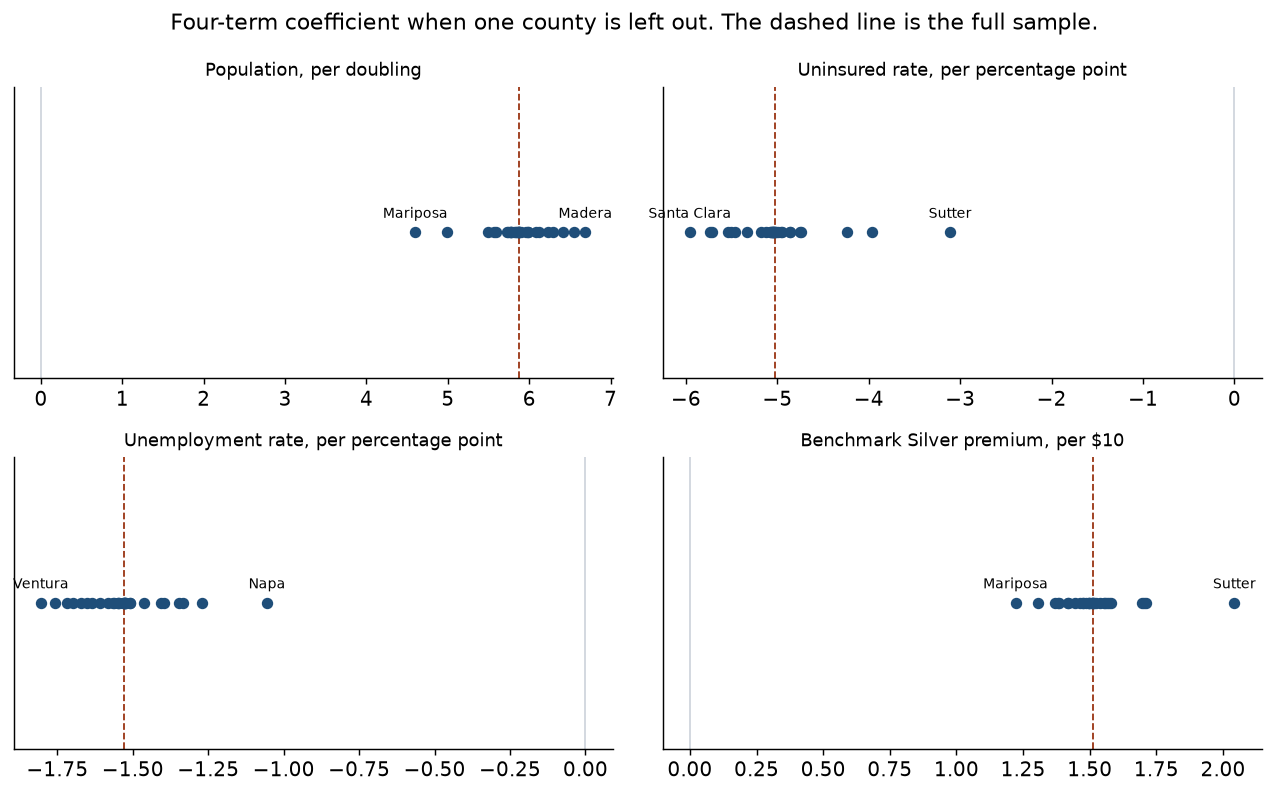

In [6]:
loo_records = []
for county_name, held_out in sample.groupby("county"):
    fit = fit_terms(FOUR_FORMULA, sample[sample["county"].ne(county_name)])
    record = {"county": county_name, "adjusted_r_squared": fit.rsquared_adj}
    for name, label, unit, scale in TERMS:
        estimate, low, high, p_value = scaled(fit, name, scale)
        record[name] = estimate
        record[f"{name}_excludes_zero"] = bool(low > 0 or high < 0)
    loo_records.append(record)
loo = pd.DataFrame(loo_records)

range_rows = []
for name, label, unit, scale in TERMS:
    full_estimate, _, _, _ = scaled(reference, name, scale)
    smallest = loo.loc[loo[name].idxmin()]
    largest = loo.loc[loo[name].idxmax()]
    flips = loo[np.sign(loo[name]) != reference_sign[name]]
    range_rows.append({
        "term": label,
        "unit": unit,
        "full sample": f"{full_estimate:.1f}",
        "lowest": f"{loo[name].min():.1f} ({smallest['county']})",
        "median": f"{loo[name].median():.1f}",
        "highest": f"{loo[name].max():.1f} ({largest['county']})",
        "sign flips": int(len(flips)),
    })
display(HTML(pd.DataFrame(range_rows).to_html(index=False)))
display(Markdown(
    f"Adjusted R² across these 31 refits runs from **{loo['adjusted_r_squared'].min():.2f}** "
    f"to **{loo['adjusted_r_squared'].max():.2f}**."
))

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (name, label, unit, scale) in zip(axes.ravel(), TERMS):
    ax.axvline(0, color="#d0d5dd", linewidth=1)
    full_estimate, _, _, _ = scaled(reference, name, scale)
    ax.axvline(full_estimate, color="#9a3412", linestyle="--", linewidth=1)
    ax.scatter(loo[name], np.zeros(len(loo)), s=28, color="#1f4e79", zorder=3)
    for extreme in (loo.loc[loo[name].idxmin()], loo.loc[loo[name].idxmax()]):
        ax.annotate(
            extreme["county"],
            (extreme[name], 0),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8,
        )
    ax.set_yticks([])
    ax.set_title(f"{label}, {unit}", fontsize=10)
fig.suptitle("Four-term coefficient when one county is left out. The dashed line is the full sample.", fontsize=12)
fig.tight_layout()


## What still holds


In [7]:
def same_sign(fit):
    return {
        label: np.sign(fit.params[name]) == reference_sign[name]
        for name, label, *_ in TERMS
    }


def excludes_zero(fit):
    flags = {}
    for name, label, unit, scale in TERMS:
        _, low, high, _ = scaled(fit, name, scale)
        flags[label] = bool(low > 0 or high < 0)
    return flags


year_sign = pd.DataFrame([same_sign(fit) for fit in year_fits.values()])
year_clear = pd.DataFrame([excludes_zero(fit) for fit in year_fits.values()])
region_sign = pd.DataFrame({region: same_sign(fit) for region, fit in region_fits.items()}).T
region_clear = pd.DataFrame({region: excludes_zero(fit) for region, fit in region_fits.items()}).T
window_sign = pd.DataFrame({label: same_sign(fit) for label, fit in window_fits.items()}).T

lines = []
lines.append(
    f"Replacing the seven-term equation with the four terms leaves adjusted R² at "
    f"**{reference.rsquared_adj:.2f}** (seven terms: **{full.rsquared_adj:.2f}**)."
)
lines.append(
    f"In the nine single years, adjusted R² runs from **{year_adj.min():.2f}** to "
    f"**{year_adj.max():.2f}**. The signs match the full-period fit in this many years: "
    + ", ".join(f"{label} **{int(year_sign[label].sum())}** of 9" for label in year_sign.columns)
    + ". The interval excludes zero in this many years: "
    + ", ".join(f"{label} **{int(year_clear[label].sum())}** of 9" for label in year_clear.columns)
    + "."
)
early = window_fits["2016–2019 averages"]
early_unclear = [label for label, clear in excludes_zero(early).items() if not clear]
late_unclear = [label for label, clear in excludes_zero(late).items() if not clear]
lines.append(
    f"The 2016–2019 averages have adjusted R² **{early.rsquared_adj:.2f}**. "
    f"The 2020–2024 averages have adjusted R² **{late.rsquared_adj:.2f}**. "
    + (
        "Both windows keep the same four signs. "
        if window_sign.all().all()
        else "A window changes at least one sign. "
    )
    + (
        f"In the early window the interval includes zero for {name_list(early_unclear)}. "
        if early_unclear
        else "In the early window every interval excludes zero. "
    )
    + (
        f"In the later window the interval includes zero for {name_list(late_unclear)}."
        if late_unclear
        else "In the later window every interval excludes zero."
    )
)

region_bits = []
for region in region_order:
    lost = [label for label in region_sign.columns if not region_sign.loc[region, label]]
    unclear = [
        label for label in region_clear.columns
        if region_sign.loc[region, label] and not region_clear.loc[region, label]
    ]
    if lost:
        region_bits.append(f"leaving out {region} flips {name_list(lost)}")
    elif unclear:
        region_bits.append(
            f"leaving out {region} keeps every sign, and the interval for {name_list(unclear)} includes zero"
        )
    else:
        region_bits.append(f"leaving out {region} keeps every sign with an interval that excludes zero")
lines.append("Region cuts: " + "; ".join(region_bits) + ".")

flip_counts = {label: int((np.sign(loo[name]) != reference_sign[name]).sum()) for name, label, *_ in TERMS}
lines.append(
    "Dropping one county never flips a sign."
    if all(count == 0 for count in flip_counts.values())
    else "Dropping one county flips a sign for "
    + ", ".join(f"{label} ({count})" for label, count in flip_counts.items() if count)
    + "."
)
lines.append(
    "Adjusted R² stays near 0.6 when the extra terms are dropped, when each year is fit on its own, "
    "and when any one county is dropped. The fit is not an artifact of averaging, and it is not one county. "
    "It does depend on which region is included. Leaving out Southern California flips the uninsured coefficient "
    "from negative to positive, and that flipped interval excludes zero. Leaving out Sacramento and the foothills "
    "flips the population coefficient, and that interval includes zero. Leaving out the Bay Area keeps the signs "
    "and lowers adjusted R² to 0.48; unemployment and the benchmark then have intervals that include zero. "
    "Kaiser's Northern and Southern California regions carry part of it. With a Southern California indicator "
    "in the equation, only population keeps an interval that excludes zero, and inside Northern California "
    "the uninsured coefficient turns positive. "
    "The 0.59 describes these 31 counties together. The separate coefficients are not a relationship that shows up "
    "inside every part of the state."
)
display(Markdown("\n\n".join(lines)))

Replacing the seven-term equation with the four terms leaves adjusted R² at **0.60** (seven terms: **0.59**).

In the nine single years, adjusted R² runs from **0.50** to **0.66**. The signs match the full-period fit in this many years: Population **9** of 9, Uninsured rate **9** of 9, Unemployment rate **9** of 9, Benchmark Silver premium **9** of 9. The interval excludes zero in this many years: Population **9** of 9, Uninsured rate **6** of 9, Unemployment rate **6** of 9, Benchmark Silver premium **6** of 9.

The 2016–2019 averages have adjusted R² **0.57**. The 2020–2024 averages have adjusted R² **0.60**. Both windows keep the same four signs. In the early window the interval includes zero for Uninsured rate and Unemployment rate. In the later window every interval excludes zero.

Region cuts: leaving out Bay Area keeps every sign, and the interval for Unemployment rate and Benchmark Silver premium includes zero; leaving out Sacramento and the foothills flips Population; leaving out San Joaquin Valley keeps every sign, and the interval for Uninsured rate includes zero; leaving out Southern California flips Uninsured rate.

Dropping one county never flips a sign.

Adjusted R² stays near 0.6 when the extra terms are dropped, when each year is fit on its own, and when any one county is dropped. The fit is not an artifact of averaging, and it is not one county. It does depend on which region is included. Leaving out Southern California flips the uninsured coefficient from negative to positive, and that flipped interval excludes zero. Leaving out Sacramento and the foothills flips the population coefficient, and that interval includes zero. Leaving out the Bay Area keeps the signs and lowers adjusted R² to 0.48; unemployment and the benchmark then have intervals that include zero. Kaiser's Northern and Southern California regions carry part of it. With a Southern California indicator in the equation, only population keeps an interval that excludes zero, and inside Northern California the uninsured coefficient turns positive. The 0.59 describes these 31 counties together. The separate coefficients are not a relationship that shows up inside every part of the state.